# TP 2 - MLP sobre 20 Newsgroups
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Consigna
A partir de la notebook de Regresión Softmax en TNG, entrenar un modelo de MLP cuya búsqueda de hiperparámetros debe incluir al menos:
- Distintas funciones de activación.
- Distintas cantidades de capas ocultas (1, 2 o 3, no más que eso).
- Distintas cantidades de neuronas por capa.
- Distintos optimizadores con distintos parámetros: Adam, RMSProp, SGD, momentos de orden 1 y 2.
- Los hiperparámetros buscados en el TP anterior (learning rate, etc.).

Además, encontrar una cantidad de unidades ocultas y capas de forma tal que el problema quede sobreajustado. Analizar lo encontrado a lo ancho de todos los entrenamientos, comparar performances y tiempos de entrenamiento.

Bonus: usar pruning en Optuna y comparar los resultados con los de la regresión softmax.

## Resolución

**Alumno:** Facundo Tomás Cassano Nieto (legajo 65555)

## 0. Setup

In [1]:
!pip install -q mlflow optuna

In [2]:
import time
import random
import logging
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import optuna

warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.WARNING)
logging.getLogger("alembic").setLevel(logging.WARNING)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# En CPU, las cuentas con números muy cercanos a cero son muy lentas; esto los redondea a 0
torch.set_flush_denormal(True)
print("Usando dispositivo:", device)

Usando dispositivo: cpu


In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos


## 2. Preprocesamiento y vectorización

Igual que en el TP1.

In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

In [6]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


## 3. Modelo: MLP

El MLP tiene entre 1 y 3 capas ocultas, y cada una puede tener una cantidad distinta de neuronas. Después de cada capa oculta se aplica la función de activación. La última capa da un valor por clase (20 logits), igual que la softmax, y la softmax la sigue aplicando `CrossEntropyLoss` por dentro.

In [7]:
ACTIVACIONES = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "elu": nn.ELU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, neuronas, activacion):
        super().__init__()
        capas = []
        entrada = input_dim
        for n in neuronas:  # una capa oculta por cada número de la lista
            capas.append(nn.Linear(entrada, n))
            capas.append(ACTIVACIONES[activacion]())
            entrada = n
        capas.append(nn.Linear(entrada, num_classes))  # capa de salida
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)


modelo_prueba = MLP(10000, NUM_CLASSES, [256, 64], "relu")
print(modelo_prueba)
print("Parámetros:", sum(p.numel() for p in modelo_prueba.parameters()))

MLP(
  (red): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=20, bias=True)
  )
)
Parámetros: 2578004


### Optimizadores
- **SGD:** da un paso en contra del gradiente. Con `momentum` (momento de orden 1) además arrastra una parte de los pasos anteriores, así no cambia tanto de dirección de un batch a otro.
- **RMSProp:** lleva un promedio de los gradientes al cuadrado (momento de orden 2, que se controla con `alpha`) y divide el paso por ese promedio. Así cada peso tiene su propio tamaño de paso. También se le puede agregar `momentum`.
- **Adam:** usa los dos momentos: `beta1` controla el promedio de los gradientes (orden 1) y `beta2` el de los gradientes al cuadrado (orden 2).

## 4. Entrenamiento

Es la misma función de entrenamiento del TP1. Le agregué el parámetro `trial` para hacer pruning: en cada época le paso a Optuna la `val_acc`, y si el trial viene peor que la mediana de los anteriores en esa misma época, Optuna lo corta.

In [8]:
%load_ext tensorboard

In [9]:
def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="mlp",
                verbose=True, trial=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        t0 = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total
        epoch_time = time.perf_counter() - t0

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
                  f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {epoch_time:.2f} s")
        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        if mlflow.active_run() is not None:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)

        # Pruning
        if trial is not None:
            trial.set_user_attr("t_entrenamiento", sum(history["epoch_time"]))
            trial.set_user_attr("epocas", epoch + 1)
            trial.set_user_attr("mejor_val_acc", max(history["val_acc"]))
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return history

## 5. Búsqueda de hiperparámetros con Optuna

Hiperparámetros:
- Preprocesamiento, vectorización, learning rate y batch size: los mismos valores que en el TP1.
- Capas ocultas: 1, 2 o 3.
- Neuronas por capa: 32, 64, 128, 256 o 512 (cada capa elige la suya).
- Activación: ReLU, LeakyReLU, ELU, tanh o sigmoide.
- Optimizador: Adam (`beta1` y `beta2`), RMSProp (`alpha` y `momentum`) o SGD (`momentum`).

Cada trial entrena 8 épocas y devuelve la mejor `val_acc` de esas épocas. Para el pruning uso `MedianPruner`, que empieza a cortar después de 5 trials completos y a partir de la tercera época.

In [10]:
mlflow.set_experiment("optuna_mlp_20newsgroups")
EPOCAS_BUSQUEDA = 8


def objective(trial):
    # Mismos hiperparámetros que en el TP1
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # Arquitectura
    n_capas = trial.suggest_int("n_capas", 1, 3)
    neuronas = [trial.suggest_categorical(f"neuronas_capa{i+1}", [32, 64, 128, 256, 512]) for i in range(n_capas)]
    activacion = trial.suggest_categorical("activacion", list(ACTIVACIONES))

    # Datos
    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=1024, shuffle=False)

    model = MLP(X_tr.shape[1], NUM_CLASSES, neuronas, activacion)

    # Optimizador
    nombre_opt = trial.suggest_categorical("optimizador", ["adam", "rmsprop", "sgd"])
    if nombre_opt == "adam":
        beta1 = trial.suggest_categorical("beta1", [0.0, 0.5, 0.9])
        beta2 = trial.suggest_categorical("beta2", [0.99, 0.999])
        optimizer = optim.Adam(model.parameters(), lr=lr, betas=(beta1, beta2))
    elif nombre_opt == "rmsprop":
        alpha = trial.suggest_categorical("alpha", [0.9, 0.99])
        momentum = trial.suggest_categorical("momentum_rms", [0.0, 0.9])
        optimizer = optim.RMSprop(model.parameters(), lr=lr, alpha=alpha, momentum=momentum)
    else:
        momentum = trial.suggest_categorical("momentum_sgd", [0.0, 0.9])
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    trial.set_user_attr("n_parametros", sum(p.numel() for p in model.parameters()))
    with mlflow.start_run(run_name=f"trial_{trial.number:02d}"):
        mlflow.log_params(trial.params)
        history = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCAS_BUSQUEDA,
                              run_name=f"trial_{trial.number}", verbose=False, trial=trial)

    trial.set_user_attr("mejor_epoca", int(np.argmax(history["val_acc"])) + 1)
    return max(history["val_acc"])

In [11]:
N_TRIALS = 40
# El estudio se guarda en un archivo para poder retomarlo si se corta la ejecución
study = optuna.create_study(
    direction="maximize", study_name="mlp", storage="sqlite:///optuna_tp2.db", load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
study.optimize(objective, n_trials=max(0, N_TRIALS - len(study.trials)))
duracion = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in study.trials if t.datetime_complete)
print(f"Tiempo de la búsqueda: {duracion / 60:.1f} min")
print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", round(study.best_value, 4))

Tiempo de la búsqueda: 8.7 min
Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.0043430719132856324, 'batch_size': 128, 'n_capas': 1, 'neuronas_capa1': 128, 'activacion': 'leaky_relu', 'optimizador': 'adam', 'beta1': 0.9, 'beta2': 0.99}
Mejor accuracy de validación: 0.7313


## 6. Análisis de la búsqueda

In [12]:
df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df.columns]
df["estado"] = df["state"].map({"COMPLETE": "completo", "PRUNED": "podado"})
df = df[df["estado"].notna()].rename(columns={"number": "trial"}).set_index("trial")  # solo trials terminados
df["s_por_epoca"] = df["t_entrenamiento"] / df["epocas"]

cols = ["value", "n_capas", "neuronas_capa1", "neuronas_capa2", "neuronas_capa3",
        "activacion", "optimizador", "lr", "batch_size", "max_features", "ngram_range", "n_parametros",
        "epocas", "t_entrenamiento"]
print("Los 10 mejores trials:")
display(df[df.estado == "completo"].sort_values("value", ascending=False)[cols].head(10).round(4))

Los 10 mejores trials:


,value,n_capas,neuronas_capa1,neuronas_capa2,neuronas_capa3,activacion,optimizador,lr,batch_size,max_features,ngram_range,n_parametros,epocas,t_entrenamiento
trial,,,,,,,,,,,,,,
25,0.7313,1,128,NaN,NaN,leaky_relu,adam,0.0043,128,10000,1gram,1282708,8,3.6919
19,0.7296,1,128,NaN,NaN,tanh,adam,0.0015,128,5000,1gram,642708,8,2.3145
34,0.7278,1,128,NaN,NaN,relu,rmsprop,0.0046,64,10000,1gram,1282708,8,5.1213
4,0.7243,1,512,NaN,NaN,leaky_relu,adam,0.0024,128,5000,1gram,2570772,8,6.5123
16,0.7216,1,512,NaN,NaN,leaky_relu,adam,0.0039,128,5000,1gram,2570772,8,6.4749
26,0.7216,1,128,NaN,NaN,leaky_relu,adam,0.0189,128,10000,1gram,1282708,8,7.0337
31,0.7212,1,512,NaN,NaN,elu,adam,0.0023,128,5000,1gram,2570772,8,6.6680
35,0.7185,1,128,NaN,NaN,relu,rmsprop,0.0074,64,10000,1gram,1282708,8,5.0966
20,0.7185,1,128,NaN,NaN,tanh,adam,0.0016,128,5000,1gram,642708,8,2.3640


In [13]:
# Incluyo también los trials podados, con la mejor val_acc que llegaron a tener
for col in ["optimizador", "n_capas", "activacion"]:
    print(f"\nSegún {col}:")
    display(df.groupby(col).agg(trials=("mejor_val_acc", "size"),
                                podados=("estado", lambda s: (s == "podado").sum()),
                                val_acc_mediana=("mejor_val_acc", "median"),
                                val_acc_max=("mejor_val_acc", "max"),
                                s_por_epoca=("s_por_epoca", "mean")).round(4))


Según optimizador:


,trials,podados,val_acc_mediana,val_acc_max,s_por_epoca
optimizador,,,,,
adam,24,13,0.6962,0.7313,0.7528
rmsprop,13,8,0.6575,0.7278,0.7016
sgd,3,2,0.0530,0.0747,0.2116



Según n_capas:


,trials,podados,val_acc_mediana,val_acc_max,s_por_epoca
n_capas,,,,,
1,26,11,0.7026,0.7313,0.7144
2,11,10,0.6646,0.6986,0.7623
3,3,2,0.0530,0.0530,0.2874



Según activacion:


,trials,podados,val_acc_mediana,val_acc_max,s_por_epoca
activacion,,,,,
elu,2,0,0.6666,0.7212,0.4972
leaky_relu,16,9,0.6821,0.7313,0.7760
relu,7,5,0.6257,0.7278,0.4643
sigmoid,7,4,0.6575,0.7181,0.7419
tanh,8,5,0.6962,0.7296,0.7462


In [14]:
podados = df[df.estado == "podado"]
print(f"Trials podados: {len(podados)} de {len(df)}")
print(f"Épocas entrenadas en total: {df['epocas'].sum()} de {len(df) * EPOCAS_BUSQUEDA} posibles sin pruning")
print(f"Tiempo de entrenamiento total: {df['t_entrenamiento'].sum() / 60:.1f} min")
print("\nImportancia de cada hiperparámetro según Optuna:")
display(pd.Series(optuna.importance.get_param_importances(study)).round(3).to_frame("importancia"))

Trials podados: 23 de 40
Épocas entrenadas en total: 206 de 320 posibles sin pruning
Tiempo de entrenamiento total: 2.4 min

Importancia de cada hiperparámetro según Optuna:


,importancia
beta1,0.297
neuronas_capa1,0.174
activacion,0.085
normalization,0.084
lr,0.072
ngram_range,0.060
optimizador,0.055
max_features,0.054
n_capas,0.054
batch_size,0.040


**Qué se ve en la búsqueda**

- La mejor configuración (trial 25) tiene una sola capa oculta de 128 neuronas con LeakyReLU, Adam (lr ≈ 0,0043), unigramas, 10.000 palabras y batch 128. Llega a 0,731 de `val_acc`.
- **Capas:** con una capa oculta los resultados fueron mejores que con dos o tres. Los 10 mejores trials tienen todos una sola capa. Las redes de 3 capas no aprendieron nada en 8 épocas: se quedaron en 0,053, que es lo mismo que adivinar al azar entre 20 clases.
- **Optimizadores:** Adam y RMSProp llegaron a valores parecidos (máximos de 0,731 y 0,728), aunque Adam tuvo mejor mediana (0,696 contra 0,658) y aparece en 7 de los 10 mejores trials. SGD no aprendió en ningún trial. Con los learning rates del TP1 (entre 0,001 y 0,1) avanza demasiado lento y 8 épocas no le alcanzan.
- **Activación:** no cambió mucho el resultado, los máximos quedaron todos entre 0,72 y 0,73.
- Según Optuna, lo que más influyó fue `beta1` (el momento de orden 1 de Adam) y la cantidad de neuronas de la primera capa.
- **Tiempos:** el tiempo crece con la cantidad de parámetros. En el top 10, una red de 128 neuronas con 5.000 palabras tarda unos 2,3 s en las 8 épocas, y una de 512 neuronas unos 6,5 s, con resultados parecidos.
- **Pruning:** se cortaron 23 de los 40 trials. Se entrenaron 206 épocas en lugar de 320, un 36 % menos, y el entrenamiento de toda la búsqueda llevó 2,4 minutos.

## 7. Sobreajuste

Para sobreajustar uso una red mucho más grande que las de la búsqueda: 3 capas ocultas de 1024 neuronas, con ReLU y Adam (lr = 0,001). La entreno 20 épocas con el mismo preprocesamiento que la mejor configuración y la comparo con la mejor red de la búsqueda.

In [15]:
best = study.best_params
neuronas_best = [best[f"neuronas_capa{i+1}"] for i in range(best["n_capas"])]
ngram_best = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)

train_texts, _ = preprocessed_cache[(best["remove_stopwords"], best["normalization"])]
tr_texts, val_texts, tr_labels, val_labels = train_test_split(
    train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target)
X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_best, best["max_features"], best["min_df"])
train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=best["batch_size"], shuffle=True)
val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=1024, shuffle=False)


def crear_optimizador(model, params):
    if params["optimizador"] == "adam":
        return optim.Adam(model.parameters(), lr=params["lr"], betas=(params["beta1"], params["beta2"]))
    if params["optimizador"] == "rmsprop":
        return optim.RMSprop(model.parameters(), lr=params["lr"], alpha=params["alpha"],
                             momentum=params["momentum_rms"])
    return optim.SGD(model.parameters(), lr=params["lr"], momentum=params["momentum_sgd"])


historias = {}

torch.manual_seed(SEED)
model = MLP(X_tr.shape[1], NUM_CLASSES, neuronas_best, best["activacion"])
historias[f"mejor red {neuronas_best}"] = train_model(model, train_loader, val_loader, crear_optimizador(model, best),
                                                      epochs=20, run_name="mejor red", verbose=False)
n_params = {f"mejor red {neuronas_best}": sum(p.numel() for p in model.parameters())}

torch.manual_seed(SEED)
model = MLP(X_tr.shape[1], NUM_CLASSES, [1024, 1024, 1024], "relu")
historias["red grande [1024, 1024, 1024]"] = train_model(model, train_loader, val_loader,
                                                         optim.Adam(model.parameters(), lr=0.001),
                                                         epochs=20, run_name="red grande relu adam", verbose=False)
n_params["red grande [1024, 1024, 1024]"] = sum(p.numel() for p in model.parameters())

for nombre, h in historias.items():
    print(f"{nombre}: {n_params[nombre]:,} parámetros | "
          f"train_acc final {h['train_acc'][-1]:.4f} | mejor val_acc {max(h['val_acc']):.4f} (época "
          f"{np.argmax(h['val_acc']) + 1}) | val_acc final {h['val_acc'][-1]:.4f} | "
          f"{np.mean(h['epoch_time']):.2f} s por época")

mejor red [128]: 1,282,708 parámetros | train_acc final 0.9729 | mejor val_acc 0.7344 (época 3) | val_acc final 0.7004 | 0.47 s por época
red grande [1024, 1024, 1024]: 12,360,724 parámetros | train_acc final 0.9739 | mejor val_acc 0.6571 (época 4) | val_acc final 0.6491 | 3.65 s por época


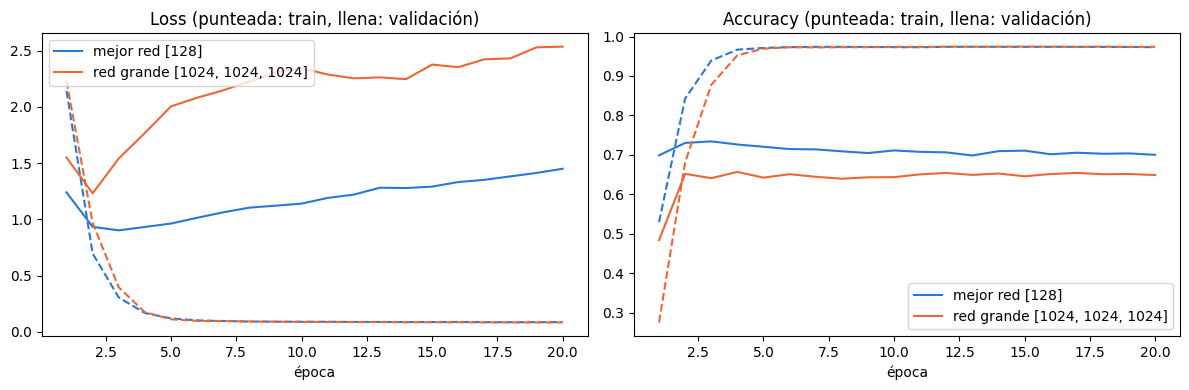

In [16]:
ep = np.arange(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (nombre, h), color in zip(historias.items(), ["#2a78d6", "#eb6834"]):
    axes[0].plot(ep, h["train_loss"], color=color, ls="--")
    axes[0].plot(ep, h["val_loss"], color=color, label=nombre)
    axes[1].plot(ep, h["train_acc"], color=color, ls="--")
    axes[1].plot(ep, h["val_acc"], color=color, label=nombre)
axes[0].set_title("Loss (punteada: train, llena: validación)")
axes[1].set_title("Accuracy (punteada: train, llena: validación)")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

La red grande queda claramente sobreajustada. En train llega a casi 0,97 de accuracy y la loss baja casi a 0, pero en validación la loss tiene su mínimo en la época 2 y después no para de subir, hasta duplicarse en la época 20. La accuracy de validación se queda en 0,65 todo el entrenamiento, unos 8 puntos menos que la mejor red, aunque tiene casi 10 veces más parámetros.

La mejor red también sobreajusta si se la deja entrenar de más: su loss de validación es mínima en la época 3 y después sube, y la accuracy de validación baja de 0,73 a 0,70. Por eso en el entrenamiento final uso pocas épocas.

## 8. Entrenamiento final

Con los mejores hiperparámetros entreno con todo el train y evalúo en test. En vez de 20 épocas como en el TP1, uso la cantidad de épocas en la que el mejor trial llegó a su mejor `val_acc`, porque el MLP empieza a sobreajustar muy rápido.

In [17]:
EPOCHS_FINAL = study.best_trial.user_attrs["mejor_epoca"]
train_texts_final, test_texts_final = preprocessed_cache[(best["remove_stopwords"], best["normalization"])]
X_train_final, X_test_final, _ = vectorize_data(train_texts_final, test_texts_final, ngram_best,
                                                best["max_features"], best["min_df"])
train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target),
                                batch_size=best["batch_size"], shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
                               batch_size=1024, shuffle=False)

torch.manual_seed(SEED)
model = MLP(X_train_final.shape[1], NUM_CLASSES, neuronas_best, best["activacion"])
writer = SummaryWriter(log_dir="runs/mlp_final")
mlflow.set_experiment("mlp_20newsgroups")
with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**best, "epochs": EPOCHS_FINAL})
    history = train_model(model, train_loader_final, test_loader_final, crear_optimizador(model, best),
                          epochs=EPOCHS_FINAL, writer=writer, run_name="final")
writer.close()

[final] Epoch 1/2 - train_loss: 1.9365 train_acc: 0.5541 - val_loss: 1.2337 val_acc: 0.6573 - 0.61 s
[final] Epoch 2/2 - train_loss: 0.6189 train_acc: 0.8482 - val_loss: 1.0782 val_acc: 0.6799 - 0.60 s


In [18]:
model.eval()
all_preds = []
with torch.no_grad():
    for xb, _ in test_loader_final:
        all_preds.extend(model(xb.to(device)).argmax(dim=1).cpu().numpy())
all_labels = newsgroups_test.target

acc_mlp = accuracy_score(all_labels, all_preds)
f1_mlp = f1_score(all_labels, all_preds, average="macro")
print(f"Accuracy en test: {acc_mlp:.4f}")
print(f"Macro-F1 en test: {f1_mlp:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

Accuracy en test: 0.6799
Macro-F1 en test: 0.6692

                          precision    recall  f1-score   support

             alt.atheism       0.47      0.53      0.50       319
           comp.graphics       0.62      0.64      0.63       389
 comp.os.ms-windows.misc       0.63      0.58      0.60       394
comp.sys.ibm.pc.hardware       0.61      0.65      0.63       392
   comp.sys.mac.hardware       0.73      0.66      0.69       385
          comp.windows.x       0.80      0.67      0.73       395
            misc.forsale       0.76      0.79      0.78       390
               rec.autos       0.63      0.73      0.68       396
         rec.motorcycles       0.84      0.67      0.74       398
      rec.sport.baseball       0.52      0.88      0.65       397
        rec.sport.hockey       0.87      0.88      0.88       399
               sci.crypt       0.82      0.72      0.77       396
         sci.electronics       0.65      0.56      0.61       393
                 sci.med

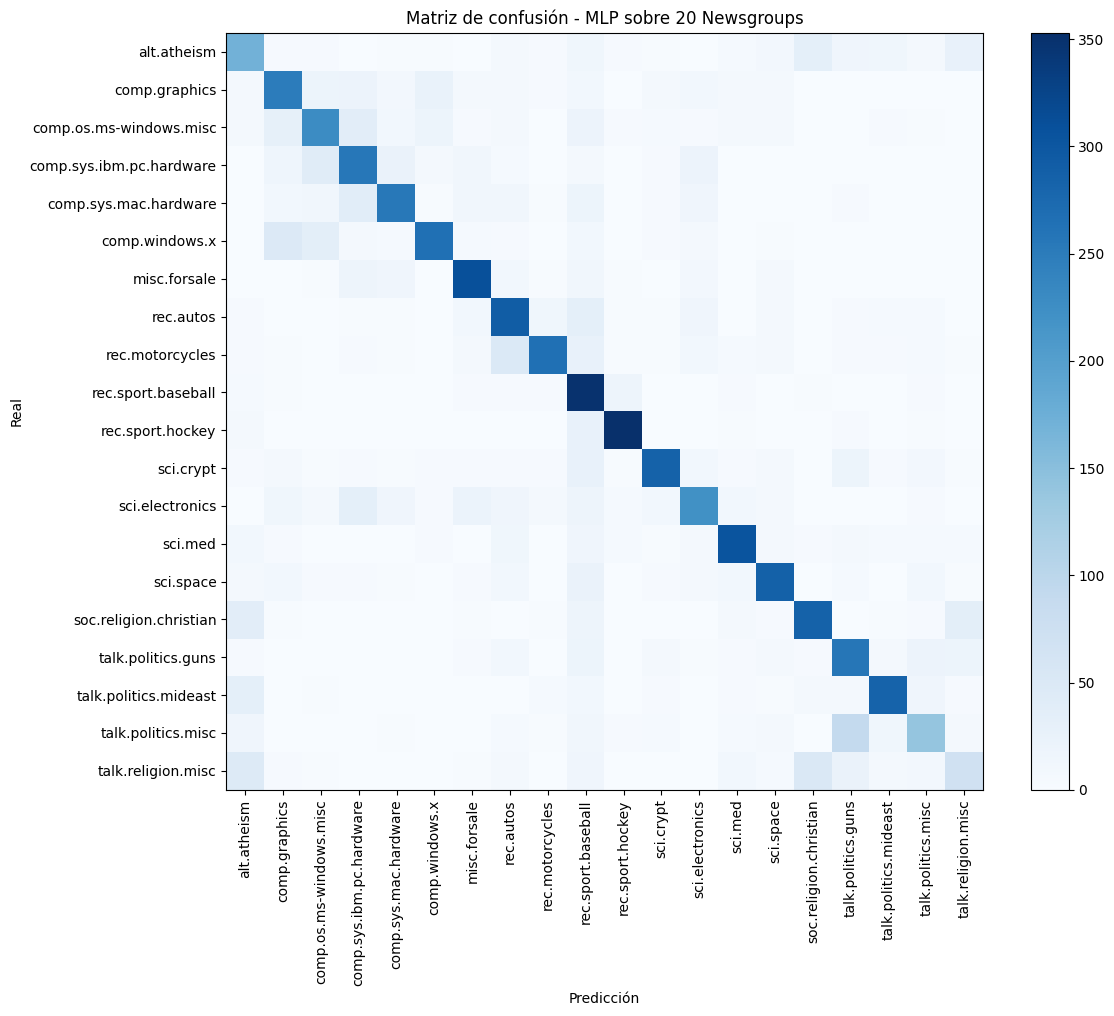

In [19]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

## 9. Comparación con regresión softmax

Para comparar en la misma máquina, vuelvo a entrenar la softmax con la mejor configuración del TP1 (20 épocas). Un MLP sin capas ocultas es justamente la regresión softmax.

In [20]:
config_tp1 = {"remove_stopwords": False, "normalization": "stem", "max_features": 10000, "min_df": 5,
              "lr": 0.0145, "batch_size": 128}
tr_sm, te_sm = preprocessed_cache[(config_tp1["remove_stopwords"], config_tp1["normalization"])]
X_tr_sm, X_te_sm, _ = vectorize_data(tr_sm, te_sm, (1, 1), config_tp1["max_features"], config_tp1["min_df"])
loader_tr_sm = DataLoader(to_tensor_dataset(X_tr_sm, newsgroups_train.target),
                          batch_size=config_tp1["batch_size"], shuffle=True)
loader_te_sm = DataLoader(to_tensor_dataset(X_te_sm, newsgroups_test.target), batch_size=1024, shuffle=False)

torch.manual_seed(SEED)
softmax = MLP(X_tr_sm.shape[1], NUM_CLASSES, [], "relu")
history_sm = train_model(softmax, loader_tr_sm, loader_te_sm, optim.Adam(softmax.parameters(), lr=config_tp1["lr"]),
                         epochs=20, run_name="softmax", verbose=False)

softmax.eval()
preds_sm = []
with torch.no_grad():
    for xb, _ in loader_te_sm:
        preds_sm.extend(softmax(xb.to(device)).argmax(dim=1).cpu().numpy())

comparacion = pd.DataFrame({
    "accuracy test": [accuracy_score(all_labels, preds_sm), acc_mlp],
    "macro-F1 test": [f1_score(all_labels, preds_sm, average="macro"), f1_mlp],
    "parámetros": [sum(p.numel() for p in softmax.parameters()), sum(p.numel() for p in model.parameters())],
    "épocas": [20, EPOCHS_FINAL],
    "s por época": [np.mean(history_sm["epoch_time"]), np.mean(history["epoch_time"])],
    "tiempo total (s)": [sum(history_sm["epoch_time"]), sum(history["epoch_time"])],
}, index=["Regresión softmax", f"MLP {neuronas_best} {best['activacion']}"])
display(comparacion.round(4))

,accuracy test,macro-F1 test,parámetros,épocas,s por época,tiempo total (s)
Regresión softmax,0.6557,0.6478,200020,20,0.2336,4.6726
MLP [128] leaky_relu,0.6799,0.6692,1282708,2,0.6034,1.2067


- El MLP llega a 0,680 de accuracy en test, contra 0,656 de la softmax: más de 2 puntos de mejora. El macro-F1 sube de 0,648 a 0,669.
- Cada época del MLP tarda más del doble (0,60 s contra 0,23 s), pero como necesita 2 épocas en vez de 20, el entrenamiento completo termina antes (1,2 s contra 4,7 s).
- La mejora existe pero es chica. Las clases donde más se equivoca el MLP siguen siendo las mismas que con la softmax en el TP1: `talk.religion.misc`, `alt.atheism` y `talk.politics.misc`, que usan palabras muy parecidas a las de otros grupos.

## 10. Conclusiones

- Para este problema alcanza con un MLP chico: una capa oculta de 128 neuronas dio el mejor resultado. Más capas no mejoraron, y las redes de 512 neuronas tardaron más sin andar mejor.
- Adam fue el optimizador que mejor funcionó en general, seguido de cerca por RMSProp; SGD necesitaría un learning rate más grande o más épocas.
- Una red grande (3 capas de 1024) sobreajusta enseguida: memoriza el train y en validación queda peor que la red chica.
- El pruning permitió probar 40 configuraciones cortando las que venían mal, y se entrenó un 36 % menos de épocas.
- El MLP mejora a la softmax en más de 2 puntos de accuracy en test.